In [1]:
%load_ext autoreload
%autoreload 2

![](../../docs/gerics.png)
# GERICS climate fact sheet - Balkenplots 

*Climate stripes* have been established by Professor Ed Hawkins, Universität Reading in 2018.

The data base is ERA5 average over each African country.
Data source: "Hersbach, H, Bell, B, Berrisford, P, et al. The ERA5 global reanalysis. Q J R Meteorol Soc. 2020; 146: 1999– 2049. https://doi.org/10.1002/qj.3803". 



**Katharina Bülow**, Climate Service Center Germany (GERICS), Helmholtz-Zentrum hereon GmbH, Email: katharina.buelow@hereon.de

In [5]:
import os

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib import colormaps
from matplotlib.colors import ListedColormap

In [6]:
import warnings
warnings.filterwarnings('ignore')

In [28]:

wkdir = os.getcwd()
datadir= wkdir.replace("ERA5", "data")
datadir = os.path.join(datadir, "spavg/spavg_era5")

plotdir = wkdir.replace("Notebooks/ERA5", "PLOTS/ERA5_anomaly")

if not os.path.exists(plotdir):
    os.makedirs(plotdir)

In [29]:
# File:
FilenameT="climdexERA5_TG_year_weighted_means_updated.csv"
FilenameNS="climdexERA5_RRm_year_weighted_means_updated.csv"
inputT=os.path.join(datadir,FilenameT)
inputNS=os.path.join(datadir,FilenameNS)

In [30]:
dfT_all = pd.read_csv(inputT)
dfNS_all = pd.read_csv(inputNS)

In [47]:
# Country selection
#country = "Ivory Coast"
#country = "Togo"
country = "Burkina Faso"
region = country.replace(" ", "_")
plotname = "ERA5_Annual_anomaly_deviation_to_1991_2020_" + region + "_nc.png"
figure_name = os.path.join(plotdir, plotname)

In [48]:
def select_region(df, country):
    return df.loc[(df["region"].isin([country]))]

In [49]:
def deviation(df, variable):
    df = df.copy()
    # robuste Zeitkonvertierung (YYYY-MM-DD und YYYY-MM-DD HH:MM:SS)
    df["time"] = pd.to_datetime(df["time"].astype(str).str.strip(), format="mixed", errors="coerce")
    df = df.dropna(subset=["time"])

    start = "1991-01-01"
    end = "2020-12-31"

    mask = (df["time"] >= start) & (df["time"] <= end)

    df_new = df[mask]
    hist = df_new["value"].mean()
    # print(hist)
    if variable != "precipitation":
        # print(df['value']-hist)
        df["Temperature anomaly [°C]"] = df["value"] - hist
    else:
        df["Precipitation anomaly [mm]"] = df["value"] - hist
        df["Precipitation change [%]"] = ((df["value"] - hist) / hist) * 100

    # just nice to have for plotting:
    df["year"] = pd.DatetimeIndex(df["time"]).year

    return df

In [50]:
dfTr = select_region(dfT_all, country)
dfTn = deviation(dfTr, "temperature")

dfNSr = select_region(dfNS_all, country)
dfNSn = deviation(dfNSr, "precipitation")

In [51]:
cmap = ListedColormap(
    [
        "#08306b",
        "#08519c",
        "#2171b5",
        "#4292c6",
        "#6baed6",
        "#9ecae1",
        "#c6dbef",
        "#deebf7",
        "#fee0d2",
        "#fcbba1",
        "#fc9272",
        "#fb6a4a",
        "#ef3b2c",
        "#cb181d",
        "#a50f15",
        "#67000d",
    ]
)

# linearly normalizes data into the [0.0, 1.0] interval
norm = mpl.colors.Normalize(
    dfTn["Temperature anomaly [°C]"].min(), dfTn["Temperature anomaly [°C]"].max()
)
norm2 = mpl.colors.Normalize(
    dfNSn["Precipitation change [%]"].min(), dfNSn["Precipitation change [%]"].max()
)

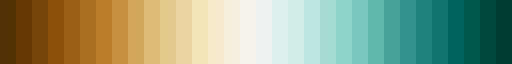

In [52]:
# https://matplotlib.org/stable/users/explain/colors/colormap-manipulation.html
BrBG = mpl.colormaps["BrBG"].resampled(32)
BrBG

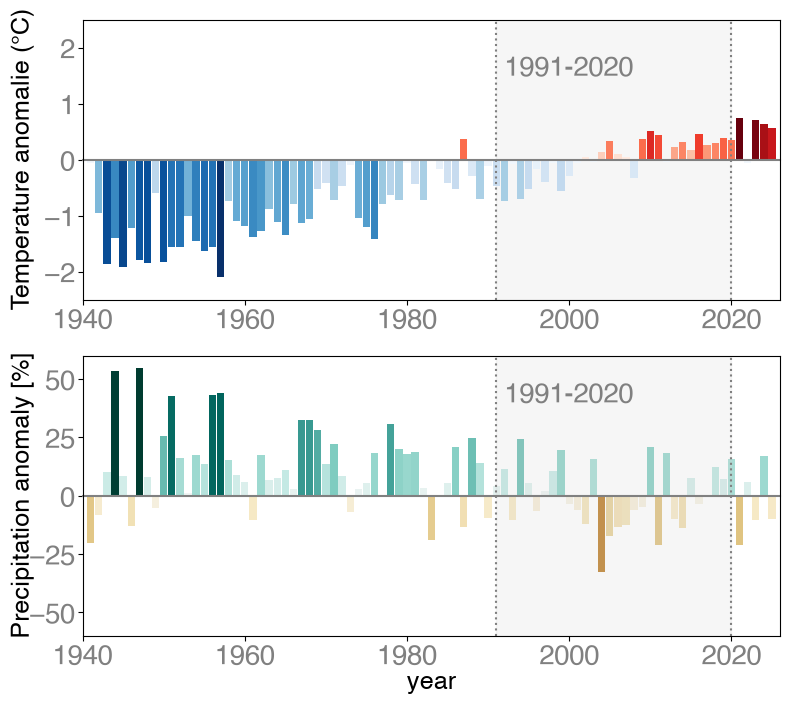

In [53]:
#Create figure and axises

# use Helvetica globally for this plot
mpl.rcParams["font.family"] = "Helvetica"
mpl.rcParams["font.sans-serif"] = ["Helvetica", "Arial", "DejaVu Sans"]

f, (ax1, ax2) = plt.subplots(2, 1, figsize=(9, 8), sharex=True)


def set_tick_params(ax):
    ax.xaxis.set_tick_params(
        pad=2,
        labelbottom=True,
        bottom=True,
        labelsize=20,
        labelrotation=0,
        labelcolor="grey",
    )
    ax.yaxis.set_tick_params(
        pad=2,
        labelleft=True,
        left=True,
        labelsize=20,
        labelrotation=0,
        labelcolor="grey",
    )
    ax.yaxis.set_label_coords(-0.07, 0.5)

# Build sign-strict colors: red for positive, blue for negative (Temperature)
vals_T = dfTn["Temperature anomaly [°C]"]
pos_mask_T = vals_T >= 0
neg_mask_T = ~pos_mask_T
pos_norm_T = mpl.colors.Normalize(vmin=0, vmax=vals_T[pos_mask_T].max() if pos_mask_T.any() else 1)
neg_norm_T = mpl.colors.Normalize(vmin=0, vmax=np.abs(vals_T[neg_mask_T]).max() if neg_mask_T.any() else 1)
reds = mpl.colormaps["Reds"]
blues = mpl.colormaps["Blues"]  # light for small |v|, dark for large negative
colors_T = []
for v in vals_T:
    if v >= 0:
        colors_T.append(reds(pos_norm_T(v)))
    else:
        colors_T.append(blues(neg_norm_T(abs(v))))

# Plot bars (Temperature)
ax1.bar(
    dfTn["year"],
    dfTn["Temperature anomaly [°C]"],
    color=colors_T,
    width=0.9,
    zorder=2,
)

ax1.set_ylabel("Temperature anomalie (°C)", fontsize=18)
#ax1.set_title(country + ": ERA5 annual anomaly compared to the mean from 1991-2020 for the years 1941 to 2023", fontsize=14)
ax1.set_xlabel("", fontsize=20, labelpad=10)
set_tick_params(ax1)
ax1.set_xlim([dfTn["year"].min() - 1, dfTn["year"].max() + 1])
ax1.set_ylim(-2.5, 2.5)

ax1.axhline(0, color="grey", clip_on=False)
ax1.axvspan(1991, 2020, alpha=0.2, color="lightgrey")
ax1.axvline(1991, color="grey", linestyle=":", clip_on=False)
ax1.axvline(2020, color="grey", linestyle=":", clip_on=False)
ax1.text(1992, 1.5, "1991-2020", size=20, color="grey")

# Niederschlag (Precipitation): use BrBG colormap centered at 0 (no colorbar)
vals_P = dfNSn["Precipitation change [%]"]
max_abs_P = float(np.nanmax(np.abs(vals_P))) if len(vals_P) else 1.0
from matplotlib.colors import TwoSlopeNorm
BrBG = mpl.colormaps["BrBG"]
# Centered normalization ensures brown for negatives, green for positives
brbg_norm = TwoSlopeNorm(vmin=-max_abs_P, vcenter=0.0, vmax=max_abs_P)
colors_P = [BrBG(brbg_norm(v)) for v in vals_P]

ax2.bar(
    dfNSn["year"],
    dfNSn["Precipitation change [%]"],
    color=colors_P,
    width=0.9,
)
ax2.set_ylabel("Precipitation anomaly [%]", fontsize=18)
ax2.axvspan(1991, 2020, alpha=0.2, color="lightgrey")
ax2.set_xlabel("year", fontsize=18, labelpad=1)
set_tick_params(ax2)

ax2.set_xlim([dfNSn["year"].min() - 1, dfNSn["year"].max() + 1])
ax2.set_ylim(-60, 60)
ax2.axhline(0, color="grey", clip_on=False)

ax2.axvline(1991, color="grey", linestyle=":", clip_on=False)
ax2.axvline(2020, color="grey", linestyle=":", clip_on=False)
ax2.text(1992, 40, "1991-2020", size=20, color="grey")

#ax2.text(
#    1940,
#    -80,
#    s="Data source: Hersbach, H, Bell, B, Berrisford, P, et al. The ERA5 global reanalysis. Q J R Meteorol Soc. 2020; 146: 1999– 2049. https://doi.org/10.1002/qj.3803.",
#    size=20,
#    color="grey",
#)
# plt.show()
plt.savefig(figure_name, dpi=1200, bbox_inches="tight")

In [54]:
figure_name

'/Users/Buelow/github/factsheet_africa/PLOTS/ERA5_anomaly/ERA5_Annual_anomaly_deviation_to_1991_2020_Burkina_Faso_nc.png'